# исследование: шаги 2–9

Шаг 2. Загрузка и разбиение на обучение и тест 

In [52]:
import numpy as np
import pandas as pd
from pathlib import Path
from sklearn.model_selection import train_test_split


df = pd.read_csv("../data/astana_rent_class.csv") 
print(df.shape) 
train, test = train_test_split(df, test_size=0.25, random_state=42) 
print(train.shape, test.shape) 


(600, 11)
(450, 11) (150, 11)


Шаг 3. Парная регрессия по формуле 

In [53]:
from sklearn.linear_model import LinearRegression 
  
tr = train.dropna(subset=["area"]) 
X = np.column_stack([np.ones(len(tr)), tr["area"]]) 
y = tr["price"].to_numpy() 

w = np.linalg.solve(X.T @ X, X.T @ y)      # (XᵀX) w = Xᵀy 
print(w.round(1)) 

lr = LinearRegression().fit(tr[["area"]], y) 
print(round(lr.intercept_, 1), lr.coef_.round(1))

[15056.3  3691. ]
15056.3 [3691.]


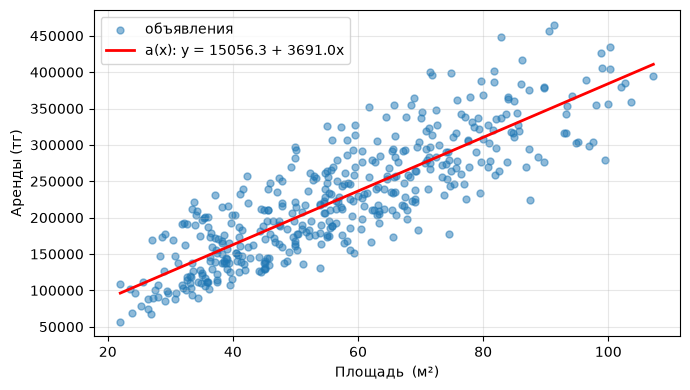

In [90]:
import matplotlib.pyplot as plt
import numpy as np
x_line = np.linspace(tr["area"].min(), tr["area"].max(), 200)
y_line = lr.predict(pd.DataFrame({"area": x_line}))
plt.figure(figsize=(7, 4))
plt.scatter(
    tr["area"], y,
    alpha=0.5,
    s=25,
    label="объявления"
)
plt.plot(
    x_line, y_line,
    color="red",
    linewidth=2,
    label=f"a(x): y = {lr.intercept_:.1f} + {lr.coef_[0]:.1f}x"
)
plt.xlabel("Площадь  (м²)")
plt.ylabel("Аренды (тг)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Шаг 4. MSE в векторной форме и качество на тесте 

In [54]:
from sklearn.metrics import mean_squared_error, r2_score 

mse = np.square(X @ w - y).mean() 

print(round(mse), round(np.sqrt(mse))) 

te = test.dropna(subset=["area"]) 

pred = lr.predict(te[["area"]]) 

print("test RMSE", round(np.sqrt(mean_squared_error(te["price"], pred))), "R2", round(r2_score(te["price"], pred), 3)) 


1894803898 43529
test RMSE 45171 R2 0.768


Шаг 5. Множественная регрессия в Pipeline 

In [55]:
from sklearn.model_selection import cross_val_score 
from sklearn.pipeline import make_pipeline 
from sklearn.compose import make_column_transformer 
from sklearn.impute import SimpleImputer 
from sklearn.preprocessing import StandardScaler, OneHotEncoder 
  
num_cols = ["rooms", "area", "floor", "floors", "year", "dist_center"] 
cat_cols = ["district", "furniture"] 
X_train, y_train = train[num_cols + cat_cols], train["price"] 
X_test,  y_test  = test[num_cols + cat_cols],  test["price"] 
  
def make_prep(num=num_cols): 
    return make_column_transformer( 
        (make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), num), 
        (make_pipeline(SimpleImputer(strategy="most_frequent"), 
                       OneHotEncoder(handle_unknown="ignore")), cat_cols)) 
  
model = make_pipeline(make_prep(), LinearRegression()) 
scores = cross_val_score(model, X_train, y_train, cv=5, scoring="r2") 
print(scores.round(3), scores.mean().round(3)) 
model.fit(X_train, y_train) 
print("test R2", round(model.score(X_test, y_test), 3)) 
  
names = [n.split("__")[1] for n in model[:-1].get_feature_names_out()] 
coefs = pd.Series(model[-1].coef_, index=names) 
print(coefs.round(0).sort_values())

[0.865 0.821 0.878 0.851 0.703] 0.824
test R2 0.871
district_Алматы     -21733.0
district_Байконур   -19289.0
district_Сарыарка   -13709.0
dist_center         -10705.0
furniture_no          -374.0
furniture_yes          374.0
floor                  687.0
year                  1685.0
floors                1759.0
rooms                13014.0
district_Нура        13463.0
district_Есиль       41268.0
area                 57252.0
dtype: float64


Шаг 6. Нелинейный признак: бинаризация расстояния 

In [62]:
from sklearn.preprocessing import KBinsDiscretizer 

num_wo = ["rooms", "area", "floor", "floors", "year"] 

def make_prep_bins(n_bins=8): 
    return make_column_transformer( 
        (make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), num_wo), 
        (KBinsDiscretizer(n_bins=n_bins, encode="onehot", strategy="uniform"), 
        ["dist_center"]), 
        (make_pipeline(SimpleImputer(strategy="most_frequent"), 
        OneHotEncoder(handle_unknown="ignore")), cat_cols)) 

model_b = make_pipeline(make_prep_bins(), LinearRegression()) 

scores = cross_val_score(model_b, X_train, y_train, cv=5, scoring="r2") 

print(scores.round(3), scores.mean().round(3)) 

model_b.fit(X_train, y_train) 

print("test", round(model_b.score(X_test, y_test), 3)) 

[0.862 0.816 0.873 0.84  0.7  ] 0.818
test 0.873


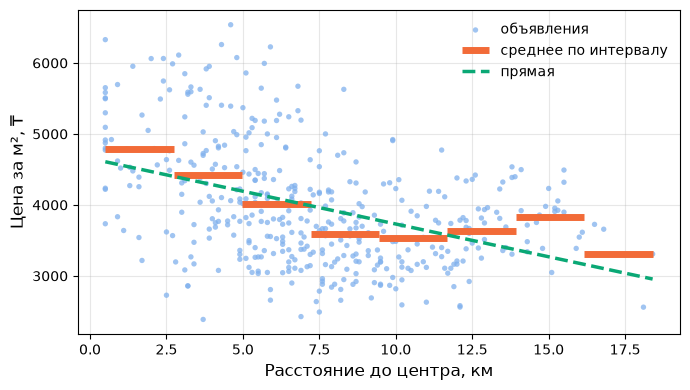

In [94]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
data = train[["dist_center", "area", "price"]].copy()
data = data.dropna()
data = data[data["area"] > 0]
data["price_m2"] = data["price"] / data["area"]
n_bins = 8
edges = np.linspace(
    data["dist_center"].min(),
    data["dist_center"].max(),
    n_bins + 1
)
data["bin"] = pd.cut(
    data["dist_center"],
    bins=edges,
    labels=False,
    include_lowest=True
)
lr_dist = LinearRegression()
lr_dist.fit(data[["dist_center"]], data["price_m2"])
x_line = np.linspace(
    data["dist_center"].min(),
    data["dist_center"].max(),
    200
)
y_line = lr_dist.predict(
    pd.DataFrame({"dist_center": x_line})
)

fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(
    data["dist_center"],
    data["price_m2"],
    color="#80B1ED",
    alpha=0.75,
    s=15,
    edgecolors="none",
    label="объявления"
)
for i in range(n_bins):
    part = data[data["bin"] == i]

    if not part.empty:
        avg = part["price_m2"].mean()

        ax.hlines(
            y=avg,
            xmin=edges[i],
            xmax=edges[i + 1],
            color="#F26B38",
            linewidth=5,
            label="среднее по интервалу" if i == 0 else None
        )
ax.plot(
    x_line,
    y_line,
    "--",
    color="#0AA875",
    linewidth=2.5,
    label="прямая"
)
ax.set_xlabel("Расстояние до центра, км", fontsize=12)
ax.set_ylabel("Цена за м², ₸", fontsize=12)

ax.grid(alpha=0.3)
ax.set_axisbelow(True)
ax.legend(loc="upper right", frameon=False)

plt.tight_layout()
plt.savefig("price_m2_distance_bins.png", dpi=300, bbox_inches="tight")
plt.show()


Шаг 7. Переобучение и регуляризация на малой выборке 

1 train RMSE 749 test RMSE 763 max|w| 276
4 train RMSE 588 test RMSE 919 max|w| 3.12e+04
15 train RMSE 522 test RMSE 186205 max|w| 1.25e+06


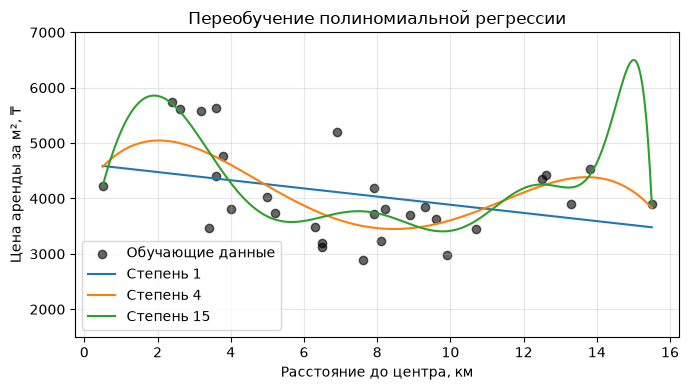

In [72]:
from sklearn.preprocessing import PolynomialFeatures 
from sklearn.linear_model import Ridge 
  
small = train.dropna(subset=["area"]).sample(30, random_state=1).copy() 
small["price_m2"] = small["price"] / small["area"] 
big = test.dropna(subset=["area"]).copy() 
big["price_m2"] = big["price"] / big["area"] 
xs, ys = small[["dist_center"]], small["price_m2"] 
  
def rmse(m, X, y): 
    return round(np.sqrt(mean_squared_error(y, m.predict(X)))) 
  
def poly(deg, reg): 
    return make_pipeline(PolynomialFeatures(deg, include_bias=False), 
                         StandardScaler(), reg) 
  
for deg in [1, 4, 15]: 
    m = poly(deg, LinearRegression()).fit(xs, ys) 
    print(deg, "train RMSE", rmse(m, xs, ys), 
          "test RMSE", rmse(m, big[["dist_center"]], big["price_m2"]), 
          "max|w|", f"{np.abs(m[-1].coef_).max():.3g}")

import matplotlib.pyplot as plt
x_plot = np.linspace(
    xs["dist_center"].min(),
    xs["dist_center"].max(),
    300
)

x_plot = pd.DataFrame({
    "dist_center": x_plot
})

plt.figure(figsize=(7, 4))
plt.scatter(
    xs["dist_center"],
    ys,
    color="black",
    alpha=0.6,
    label="Обучающие данные"
)
for deg in [1, 4, 15]:
    m = poly(deg, LinearRegression()).fit(xs, ys)

    plt.plot(
        x_plot["dist_center"],
        m.predict(x_plot),
        label=f"Степень {deg}"
    )
plt.xlabel("Расстояние до центра, км")
plt.ylabel("Цена аренды за м², ₸")
plt.title("Переобучение полиномиальной регрессии")
plt.ylim(1500, 7000)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


ridge 0.01 train 612 test 975 max|w| 3.58e+03
ridge 1 train 635 test 2387 max|w| 674
ridge 100 train 772 test 772 max|w| 60.6


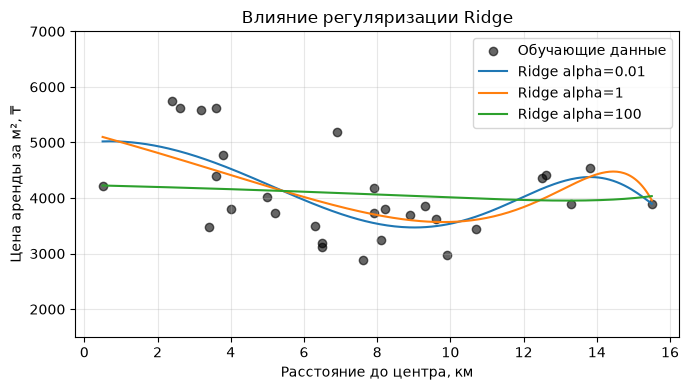

In [71]:
for a in [0.01, 1, 100]: 
    m = poly(15, Ridge(alpha=a)).fit(xs, ys) 
    print("ridge", a, "train", rmse(m, xs, ys), 
          "test", rmse(m, big[["dist_center"]], big["price_m2"]), 
          "max|w|", f"{np.abs(m[-1].coef_).max():.3g}")

plt.figure(figsize=(7, 4))
plt.scatter(
    xs["dist_center"],
    ys,
    color="black",
    alpha=0.6,
    label="Обучающие данные"
)
for a in [0.01, 1, 100]:
    m = poly(15, Ridge(alpha=a)).fit(xs, ys)

    plt.plot(
        x_plot["dist_center"],
        m.predict(x_plot),
        label=f"Ridge alpha={a}"
    )
plt.xlabel("Расстояние до центра, км")
plt.ylabel("Цена аренды за м², ₸")
plt.title("Влияние регуляризации Ridge")
plt.ylim(1500, 7000)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


Шаг 8. Ridge и Lasso с подбором α 

ridge alpha 2.593 cv 0.8201 test 0.874 zeros 0 of 20
lasso alpha 221.222 cv 0.819 test 0.875 zeros 5 of 20


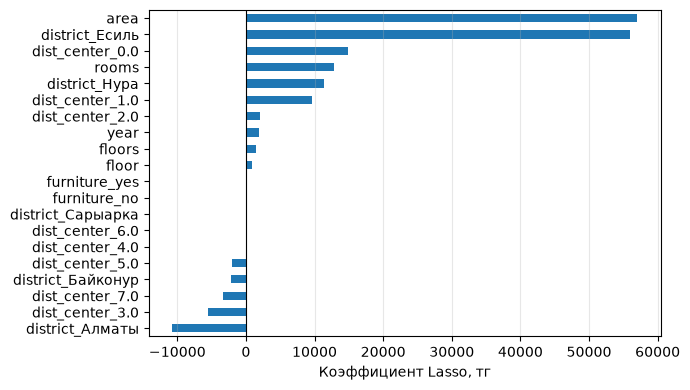

In [95]:
from sklearn.linear_model import RidgeCV, LassoCV 
import matplotlib.pyplot as plt

regs = { 
    "ridge": RidgeCV(alphas=np.logspace(-2, 3, 30)), 
    "lasso": LassoCV(alphas=np.logspace(0, 4, 30), cv=5, 
                     random_state=42, max_iter=50000), 
} 
for name, reg in regs.items(): 
    m = make_pipeline(make_prep_bins(), reg) 
    cv = cross_val_score(m, X_train, y_train, cv=5, scoring="r2").mean() 
    m.fit(X_train, y_train) 
    zeros = int((np.abs(m[-1].coef_) < 1e-6).sum()) 
    print(name, "alpha", round(m[-1].alpha_, 3), "cv", cv.round(4), 
          "test", round(m.score(X_test, y_test), 3), 
          "zeros", zeros, "of", len(m[-1].coef_)) 
lasso = m   # последняя модель цикла — Lasso 

names = [n.split("__")[1] for n in lasso[:-1].get_feature_names_out()]
coefs = pd.Series(lasso[-1].coef_, index=names)
plt.figure(figsize=(7, 4))
coefs.sort_values().plot(kind="barh")
plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("Коэффициент Lasso, тг")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

Шаг 9. Интерпретация: важность через удаление признака 

0.824
district       0.102
area           0.084
dist_center    0.006
rooms          0.004
year          -0.000
floors        -0.000
furniture     -0.000
floor         -0.001
dtype: float64


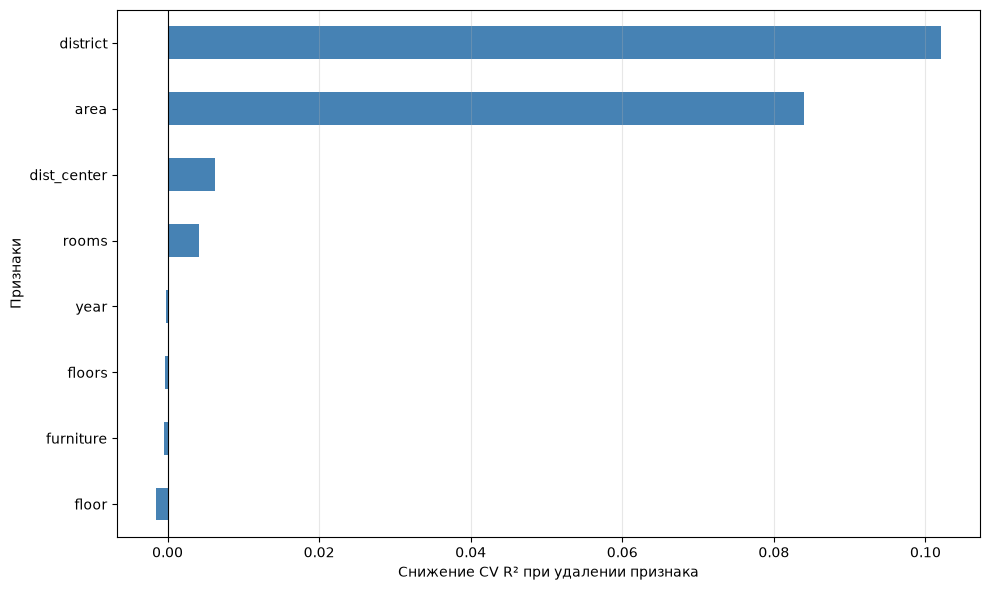

In [96]:
import matplotlib.pyplot as plt

base = cross_val_score(make_pipeline(make_prep(), Ridge(alpha=1)), 
X_train, y_train, cv=5, scoring="r2").mean() 
drop = {} 
for col in num_cols + cat_cols: 
    nn = [c for c in num_cols if c != col] 
    cc = [c for c in cat_cols if c != col] 
    prep = make_column_transformer( 
        (make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), nn), 
        (make_pipeline(SimpleImputer(strategy="most_frequent"), OneHotEncoder(handle_unknown="ignore")), cc)) 
    s = cross_val_score(make_pipeline(prep, Ridge(alpha=1)), 
        X_train, y_train, cv=5, scoring="r2").mean() 
    drop[col] = base - s 
print(round(base, 3)) 
print(pd.Series(drop).sort_values(ascending=False).round(3)) 



importance = pd.Series(drop).sort_values()
plt.figure(figsize=(10, 6))
importance.plot(kind="barh", color="steelblue")
plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("Снижение CV R² при удалении признака")
plt.ylabel("Признаки")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()


Шаг 10. Параметры и скрипт обучения 

(.venv) PS C:\Users\User\Projects\pad-lab8> python src/train.py  
linear {'cv_r2': 0.8237, 'test_r2': 0.8709, 'test_rmse': 33731, 'test_mae': 24970}  

(.venv) PS C:\Users\User\Projects\pad-lab8> cat metrics.json  
{  
  "cv_r2": 0.8237,  
  "test_r2": 0.8709,  
  "test_rmse": 33731,  
  "test_mae": 24970  
}  

Шаг 11. Фиксация базовой модели 

Шаг 13. Слияние и версия модели

(.venv) PS C:\Users\User\Projects\pad-lab8> git diff main exp/bins-ridge -- metrics.json  
diff --git a/metrics.json b/metrics.json  
index 282d135..89e86f7 100644  
--- a/metrics.json  
+++ b/metrics.json  
@@ -1,6 +1,6 @@  
 {
-  "cv_r2": 0.8237,  
-  "test_r2": 0.8709,  
-  "test_rmse": 33731, 
-  "test_mae": 24970  
+  "cv_r2": 0.8197,  
+  "test_r2": 0.8737,  
+  "test_rmse": 33372,  
+  "test_mae": 24788  
 }  

Шаг 14. Использование модели 

In [85]:
import joblib

model = joblib.load("../models/model.joblib") 

flat = pd.DataFrame([dict(rooms=2, area=60, floor=5, floors=12, year=2015, 
                          dist_center=3.0, district="Есиль", furniture="yes")]) 

print(round(model.predict(flat)[0])) 

283861
